# 04 · Property modelling

Fills the grid from notebook 03 with porosity and the clean-rock indicator using ordinary kriging
([Matheron 1963](https://doi.org/10.2113/gsecongeo.58.8.1246)), sequential Gaussian simulation
([Gómez-Hernández & Journel 1993](https://doi.org/10.1007/978-94-011-1739-5_8)), sequential indicator simulation
([Journel 1983](https://doi.org/10.1007/BF01031292)), and machine-learning propagation with quantile regression
forests (Meinshausen 2006, *Quantile Regression Forests*, JMLR 7) or LightGBM. Run notebook 03 first.

## Setup
Set `SX_EXAMPLE_PROJECT` to your KGS project folder (default `kgs_project/` next to this notebook).

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.parquet as pq
import matplotlib.pyplot as plt
%matplotlib inline
# SX_EXAMPLE_PROJECT: KGS project folder (las/, edges/, project.toml), see scripts/fetch_open_data.sh.
# SX_EXAMPLE_OUT: folder for figures and the small model files passed between notebooks.
PROJ = Path(os.environ.get("SX_EXAMPLE_PROJECT", "kgs_project")).resolve()
OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")

## Load the upscaled cells and fit a variogram
Depth is stretched 50× so a 5 m vertical step weighs like 250 m laterally.

{'kind': 'spherical',
 'nugget': 0.00025106407162197013,
 'psill': 0.0032016274361809298,
 'range': 2634.9950967880295}

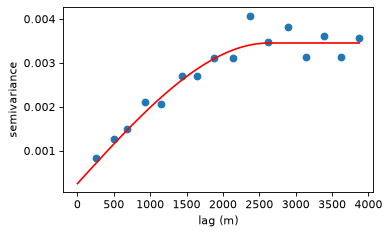

In [2]:
import subsurfix as sx
from subsurfix import _native as nat
g = np.load(OUT / "grid_upscaled.npz")
origin, cell, dims = tuple(g["origin"]), tuple(g["cell"]), tuple(int(v) for v in g["dims"])
idx, phi_up, idf, clean_up = g["idx"], g["phi_up"], g["idf"], g["clean_up"]
C = nat.grid_centers(origin, cell, dims)
S = np.array([1.0, 1.0, 50.0])
lag, gam, npair = nat.experimental_variogram(C[idx] * S, phi_up, 250.0, 16)
vg = nat.fit_variogram(lag, gam, npair, "spherical")
fig, ax = plt.subplots(figsize=(5, 3)); ax.plot(lag, gam, "o")
h = np.linspace(0, lag.max(), 100); hr = np.minimum(h / vg["range"], 1)
ax.plot(h, vg["nugget"] + vg["psill"] * (1.5 * hr - 0.5 * hr ** 3), "r-"); ax.set_xlabel("lag (m)"); ax.set_ylabel("semivariance")
save(fig, "04_variogram.png"); vg

## Kriging, SGS, SIS and ML propagation

In [3]:
ok, okv = nat.ordinary_kriging(C[idx] * S, phi_up, C * S, vg["kind"], vg["nugget"], vg["psill"], vg["range"])
real = nat.sgs(C[idx] * S, phi_up, C * S, vg["kind"], vg["nugget"], vg["psill"], vg["range"], n_realizations=8, seed=1)
fac = nat.sis(C[idf] * S, clean_up, C * S, "spherical", 0.05, 0.2, 2000.0, n_realizations=8, seed=2)
cfg = sx.Project(PROJ / "project.toml").config["propagation"]
X = np.column_stack([C, ok])
q = nat.ml_propagation(X[idx], phi_up, X, model=cfg["method"], quantiles=cfg["quantiles"], n_trees=cfg["qrf_trees"], min_leaf=3, seed=3)
print("SGS", real.shape, "| SIS", fac.shape, "| ML quantiles", q.shape)

SGS (8, 5808) | SIS (8, 5808) | ML quantiles (5808, 3)


## Maps of one layer
Grid layer 5, 20-25 m below the Mississippian top (the top of the Mississippian carbonates, mapped in notebook 03;
952-1029 m below sea level in these 60 wells). The four copper panels share one porosity scale (0-0.2).

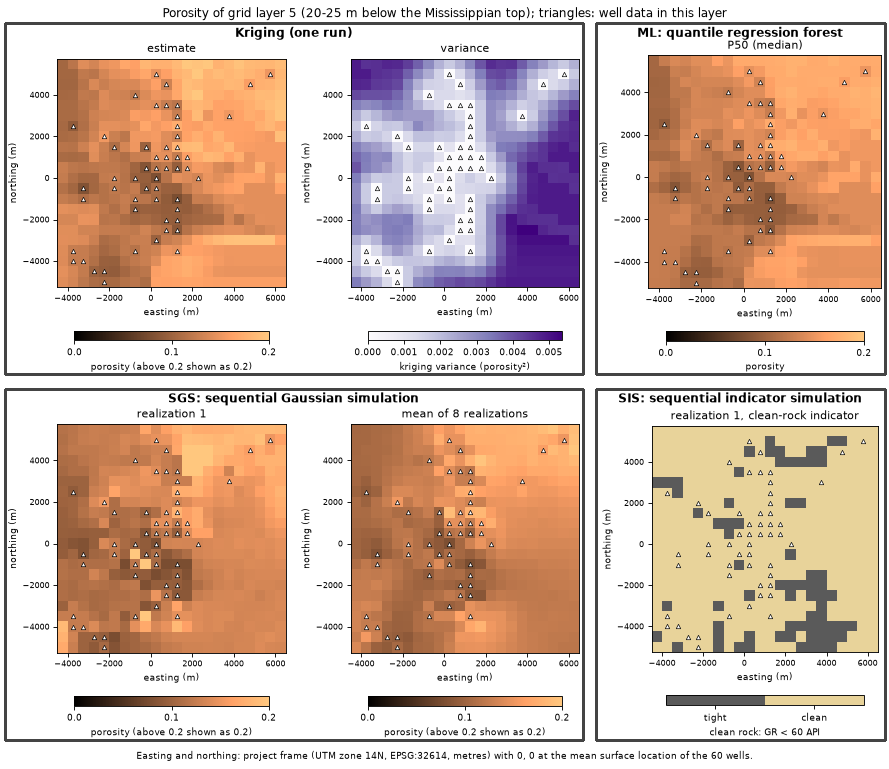

In [4]:
k = 4
sh = lambda v: np.asarray(v).reshape(dims[2], dims[1], dims[0])[k]
ext = [origin[0], origin[0] + dims[0] * cell[0], origin[1], origin[1] + dims[1] * cell[1]]
lay = np.asarray(idx) // (dims[0] * dims[1]) == k
cond = C[np.asarray(idx)[lay]][:, :2]                                   # cells with well data in this layer
from matplotlib.colors import ListedColormap
# panels grouped by method: one framed box per method, no line inside a method
groups = [("Kriging (one run)", [("estimate", sh(ok), "phi"), ("variance", sh(okv), "var")]),
          ("ML: quantile regression forest", [("P50 (median)", sh(q[:, len(cfg["quantiles"]) // 2]), "phi")]),
          ("SGS: sequential Gaussian simulation", [("realization 1", sh(real[0]), "phi"), ("mean of 8 realizations", sh(real.mean(0)), "phi")]),
          ("SIS: sequential indicator simulation", [("realization 1, clean-rock indicator", sh(fac[0]), "sis")])]
fig = plt.figure(figsize=(11, 9.2), layout="constrained")
rows = fig.subfigures(2, 1, hspace=0.04)
boxes = [b for r in rows for b in r.subfigures(1, 2, width_ratios=[2, 1], wspace=0.03)]
for box, (gname, panels) in zip(boxes, groups):
    box.set_edgecolor("#444444"); box.set_linewidth(1.2)        # frame: one box per method
    box.suptitle(gname, fontsize=10.5, fontweight="bold")
    for sf, (t, v, kind) in zip(box.subfigures(1, len(panels), wspace=0.02) if len(panels) > 1 else [box], panels):
        ax = sf.subplots()
        if kind == "phi":
            im = ax.imshow(v, origin="lower", extent=ext, cmap="copper", vmin=0.0, vmax=0.2)
            cb = sf.colorbar(im, ax=ax, location="bottom", shrink=0.85, ticks=[0, 0.1, 0.2])
            cb.set_label("porosity" + (" (above 0.2 shown as 0.2)" if float(np.nanmax(v)) > 0.2 else ""), fontsize=8)
        elif kind == "var":
            im = ax.imshow(v, origin="lower", extent=ext, cmap="Purples")
            cb = sf.colorbar(im, ax=ax, location="bottom", shrink=0.85)
            cb.set_label("kriging variance (porosity²)", fontsize=8)
        else:
            im = ax.imshow(v, origin="lower", extent=ext, cmap=ListedColormap(["#5a5a5a", "#e8d39a"]), vmin=-0.5, vmax=1.5)
            cb = sf.colorbar(im, ax=ax, location="bottom", shrink=0.85, ticks=[0, 1])
            cb.ax.set_xticklabels(["tight", "clean"]); cb.set_label("clean rock: GR < 60 API", fontsize=8)
        cb.ax.tick_params(labelsize=8)
        ax.plot(cond[:, 0], cond[:, 1], "^", ms=4, mfc="white", mec="black", mew=0.6)
        ax.set_title(t, fontsize=9.5); ax.set_aspect("equal"); ax.tick_params(labelsize=7)
        ax.set_xlabel("easting (m)", fontsize=8); ax.set_ylabel("northing (m)", fontsize=8)
fig.suptitle(f"Porosity of grid layer {k + 1} ({k * 5}-{k * 5 + 5} m below the Mississippian top); triangles: well data in this layer", fontsize=11)
fig.text(0.5, -0.015, "Easting and northing: project frame (UTM zone 14N, EPSG:32614, metres) with 0, 0 at the mean surface "
         "location of the 60 wells.", ha="center", va="top", fontsize=8)
save(fig, "04_property_maps.png")

| Map | What it is | Follows |
|---|---|---|
| Kriging | The best linear estimate from nearby wells, weighted by the fitted variogram; smooth. | [Matheron 1963](https://doi.org/10.2113/gsecongeo.58.8.1246); Journel & Huijbregts 1978, *Mining Geostatistics* |
| Kriging variance | How uncertain the kriging estimate is: low at wells, high far from them. | as kriging |
| SGS | Sequential Gaussian simulation: one equally likely map with the data's spread and variogram; the mean of many approaches kriging. | Deutsch & Journel 1998, *GSLIB* (2nd ed.); [Gómez-Hernández & Journel 1993](https://doi.org/10.1007/978-94-011-1739-5_8) |
| SIS | Sequential indicator simulation of a category, here clean (GR < 60 API) or tight rock. | [Journel 1983](https://doi.org/10.1007/BF01031292); Deutsch & Journel 1998, *GSLIB* |
| ML P50 | Median of a quantile regression forest trained on the cells the wells cross, with position and kriging as inputs. | Meinshausen 2006, *Quantile Regression Forests*, JMLR 7 |

All five are SubsurfiX's own Rust implementations based on these methods, not wrappers of another package.

## Save the model
SGS realization 1 and SIS realization 1 are used by notebooks 05 and 08.

In [5]:
np.savez_compressed(OUT / "property_model.npz", phi=real[0], clean=fac[0], ok=ok)
print(f"porosity mean {real[0].mean():.3f}, clean share {fac[0].mean():.2f}")

porosity mean 0.130, clean share 0.89
